# 6. Edge cases, chaos, gas, security
Section 2 edge cases as pass/fail checks, extreme price paths, the chaos run, gas and the security checks on the real bytecode.

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

In [2]:
c = load("edge_checks"); print("failed:", sum(r["ok"] != "true" for r in c), "of", len(c)); show(c, ["group","rules","case","observed","ok"], limit=60)

failed: 0 of 36
group      | rules | case                                       | observed                                                                    | ok  
-----------+-------+--------------------------------------------+-----------------------------------------------------------------------------+-----
      time |   v07 |                   chain_halt_window_frozen |                                      repay true close true window_end 17200 | true
      time |   v07 |                late_mature_repay_before_it |                                                 repay true window_end 27200 | true
      time |   v07 |                   shared_window_per_expiry |                                                              17200 vs 17200 | true
      time |   v07 |                repay_last_block_then_close |                                                              true true true | true
      time |   v07 |                            repay_beats_bid |                         

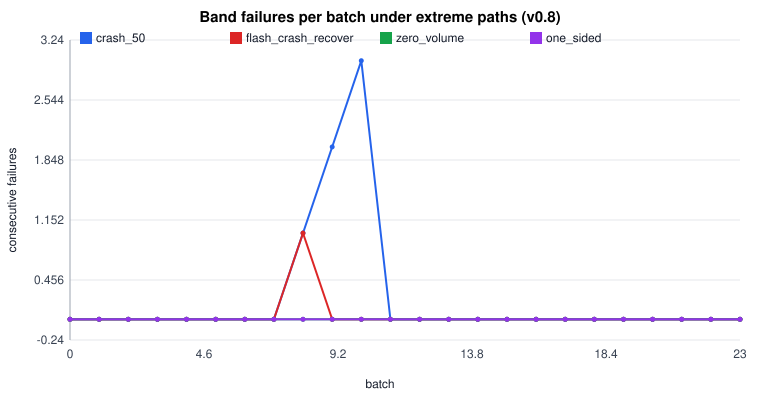

In [3]:
svg("extreme_band_failures.svg")  # band failures under extreme paths

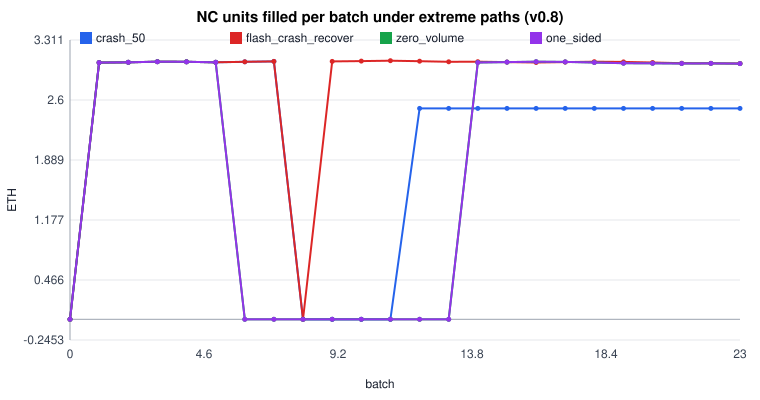

In [4]:
svg("extreme_nc_units.svg")  # NC fills under extreme paths

In [5]:
show(load("edge_extreme"), ["batch","ref_price","traded","price","nc_units","band_failures","breaker_tripped","no_trade_reason"], where=lambda r: r["rules"] == "v08" and r["path"] == "crash_50")

batch | ref_price | traded | price | nc_units | band_failures | breaker_tripped | no_trade_reason
------+-----------+--------+-------+----------+---------------+-----------------+----------------
    0 |     3,302 |   true | 3,294 |        0 |             0 |           false |                
    1 |     3,294 |   true | 3,286 |    3.043 |             0 |           false |                
    2 |     3,291 |   true | 3,282 |    3.047 |             0 |           false |                
    3 |     3,282 |   true | 3,274 |    3.054 |             0 |           false |                
    4 |     3,284 |   true | 3,276 |    3.052 |             0 |           false |                
    5 |     3,290 |   true | 3,282 |    3.047 |             0 |           false |                
    6 |     3,285 |   true | 3,276 |    3.052 |             0 |           false |                
    7 |     3,279 |   true | 3,271 |    3.057 |             0 |           false |                
    8 |     1,640 | 

## Chaos
Random actors, keeper outages, pauses, rollovers, bids and an attacker over 8 expiries × 4 strikes; every step checks ARCHITECTURE §2.11 #1/#2 and the asset = unrepaid R identity.

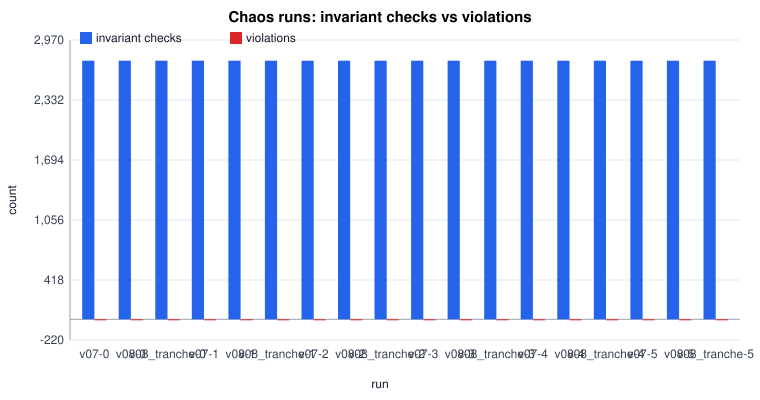

In [6]:
svg("chaos.svg")  # invariant checks vs violations per run

In [7]:
show(load("chaos"), ["rules","seed","pools","batches_settled","batches_skipped_keeper_down","orders_placed","rollovers","bids","pauses","invariant_checks","invariant_violations","stranded_quote_usdc","stranded_asset_eth"])

rules       | seed | pools | batches_settled | batches_skipped_keeper_down | orders_placed | rollovers | bids | pauses | invariant_checks | invariant_violations | stranded_quote_usdc | stranded_asset_eth
------------+------+-------+-----------------+-----------------------------+---------------+-----------+------+--------+------------------+----------------------+---------------------+-------------------
        v07 |    0 |    32 |       1.796e+04 |                       2,124 |     1.465e+04 |       327 |   75 |     14 |            2,750 |                    0 |                   0 |                  0
        v08 |    0 |    32 |       1.796e+04 |                       2,104 |     1.468e+04 |       324 |   62 |     15 |            2,750 |                    0 |                   0 |                  0
v08_tranche |    0 |    32 |       1.796e+04 |                       2,104 |     1.468e+04 |       324 |   62 |     15 |            2,750 |                    0 |                   0 |

## Gas (revm, real bytecode)

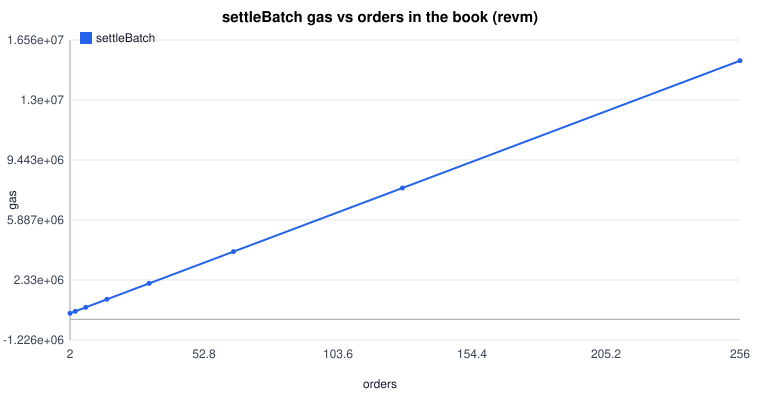

In [8]:
svg("gas_settle.svg")  # settleBatch gas vs orders

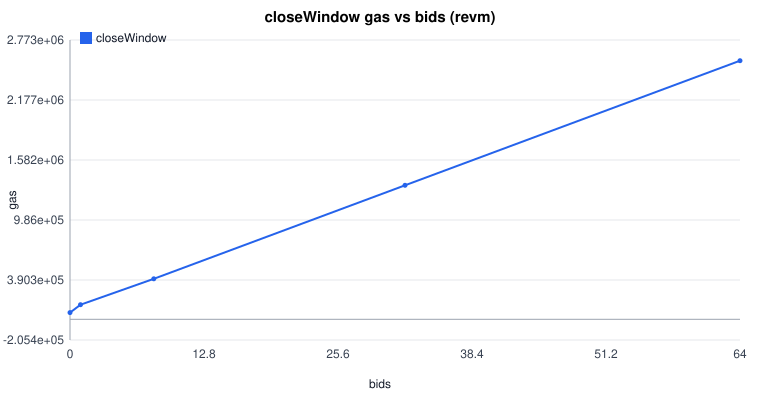

In [9]:
svg("gas_close.svg")  # closeWindow gas vs bids

In [10]:
show(load("gas")); show(load("keeper_cost"))

op          | n   | gas        | place_gas_avg
------------+-----+------------+--------------
settleBatch |   2 |  3.589e+05 |     1.801e+05
settleBatch |   4 |  4.768e+05 |     1.679e+05
settleBatch |   8 |  7.125e+05 |     1.617e+05
settleBatch |  16 |  1,184,051 |     1.587e+05
settleBatch |  32 |  2,127,110 |     1.572e+05
settleBatch |  64 |  4,013,240 |     1.564e+05
settleBatch | 128 |  7,785,547 |      1.56e+05
settleBatch | 256 | 15,330,354 |     1.558e+05
closeWindow |   0 |  6.704e+04 |             0
closeWindow |   1 |  1.455e+05 |     1.589e+05
closeWindow |   8 |  4.024e+05 |     1.485e+05
closeWindow |  32 |  1,330,404 |     1.474e+05
closeWindow |  64 |  2,567,728 |     1.473e+05
chain         | batch_seconds | settles_per_day_per_pool | gas_per_settle_typical | gas_per_day_per_pool_m
--------------+---------------+--------------------------+------------------------+-----------------------
        Monad |         1,800 |                       48 |              1,184,051

## Security checks (real bytecode)
Reentrancy through the flash-loan callback and through a hostile token, dust-order griefing at the 128-order cap, bid spam at MAX_BIDS; AUDIT M-1 (band tier chosen by the first creator) in the model.

In [11]:
s = load("security_checks"); print("failed:", sum(r["ok"] != "true" for r in s), "of", len(s)); show(s, ["group","case","observed","ok"])

failed: 0 of 13
group                     | case                                  | observed                                                                | ok  
--------------------------+---------------------------------------+-------------------------------------------------------------------------+-----
reentrancy_flash_callback |                     inner_settleBatch |                              outer_ok true inner_ok false settleCount 1 | true
reentrancy_flash_callback |                           inner_repay |                              outer_ok true inner_ok false settleCount 1 | true
reentrancy_flash_callback |                        inner_withdraw |                              outer_ok true inner_ok false settleCount 1 | true
reentrancy_flash_callback |                      inner_placeOrder |                              outer_ok true inner_ok false settleCount 1 | true
reentrancy_flash_callback |                inner_flashLoan_nested |                              outer

In [12]:
show(load("security_m1_band"))

rules | pool_band_bps | honest_band_bps | attacker_price_offset_pct | nc_filled_in_attacker_pool | nc_filled_in_honest_pool | pools_coexist
------+---------------+-----------------+---------------------------+----------------------------+--------------------------+--------------
  v07 |         1,500 |             150 |                         1 |                       true |                    false |         false
  v07 |         1,500 |             150 |                         2 |                       true |                    false |         false
  v07 |         1,500 |             150 |                         4 |                       true |                    false |         false
  v08 |         1,500 |             150 |                         1 |                       true |                     true |          true
  v08 |         1,500 |             150 |                         2 |                       true |                    false |          true
  v08 |         1,50